In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

In [ ]:
# I80
load1 = pd.read_csv('Car80_S1.csv', header=0)
load2 = pd.read_csv('Car80_S2.csv', header=0)
load3 = pd.read_csv('Car80_S3.csv', header=0)

# US101
# load1 = pd.read_csv('Car101_S1.csv', header=0)
# load2 = pd.read_csv('Car101_S2.csv', header=0)
# load3 = pd.read_csv('Car101_S3.csv', header=0)

df1 = pd.DataFrame(load1)
df2 = pd.DataFrame(load2)
df3 = pd.DataFrame(load3)
# Vertically concatenate the three datasets
all_data = pd.concat([df1, df2, df3], axis=0, ignore_index=True)
# all_data

In [ ]:
class Segmentation():
    def __init__(self,all_data,desired_vehicle_id):
        self.all_data = all_data
        self.unique_vehicle_ids = all_data['VehicleID_x'].unique()
        self.desired_vehicle_id = desired_vehicle_id

    def cal_inflection_points(self,data):
        local_minima = argrelextrema(data, np.less)
        local_maxima = argrelextrema(data, np.greater)
        inflection_points = np.sort(np.concatenate((local_minima[0], local_maxima[0])))
        inflection_indexs = [i for i in inflection_points]
        inflection_indexs.insert(0,0)
        inflection_indexs.append(len(data)-1)
        inflection_coordinates = [data[i] for i in inflection_indexs]
        delta_x = np.diff(inflection_indexs)
        delta_y = np.diff(inflection_coordinates)
        delta_x = np.append(delta_x, 0)
        delta_y = np.append(delta_y, 0)

        return inflection_indexs, inflection_coordinates,delta_x,delta_y

    def generate_result_dataset(self,variables): #variables: Velocity_x, Acceleration_x, distance, delta_v
        results = []
        for vehicle_id in self.unique_vehicle_ids:
            vehicle_data = all_data[all_data['VehicleID_x'] == vehicle_id]
            time_id = vehicle_data['FrameID'].values
            speed = vehicle_data[str(variables)].values
            inflection_points, inflection_coordinates, delta_x, delta_y = self.cal_inflection_points(speed)
            inflection_time_ids = [time_id[i] for i in inflection_points]
            result_data = pd.DataFrame({
                'VehicleID': vehicle_id,
                'InflectionTimeID': inflection_time_ids,
                'InflectionSpeed': inflection_coordinates,
                'DeltaX': delta_x,
                'DeltaY': delta_y
            })
            results.append(result_data)
        result_dataset = pd.concat(results, ignore_index=True)
        return result_dataset

    def find_data(self,result_dataset):
        single_vehicle_result = result_dataset[result_dataset['VehicleID'] == self.desired_vehicle_id]
        single_vehicle_data = all_data[all_data['VehicleID_x'] == self.desired_vehicle_id]
        delta_t = single_vehicle_result['DeltaX'].values
        delta_y = single_vehicle_result['DeltaY'].values
        time_turning_points = single_vehicle_result['InflectionTimeID'].values
        turning_points_values = single_vehicle_result['InflectionSpeed'].values
        return single_vehicle_data,delta_t,delta_y,time_turning_points,turning_points_values

    def get_states_set(self,delta_y,theta1,theta2):
        states = []
        # try 1 st
        for dy in delta_y:
            if dy >= theta1:
                state = 'I'
            elif dy <= theta2:
                state = 'D'
            else:
                state = 'K'
            states.append(state)
        return states

    def merge(self,states,delta_t,delta_y,time_turning_points,theta1,theta2,gama):
        merged_index_set = []
        for index, j in enumerate(states):
            if index < 1:
                if states[index+1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
            elif index == len(states)-1:
                if states[index-1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
            else:
                if states[index-1] != j and states[index+1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
                elif states[index-1] == j and states[index+1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
                elif states[index+1] == j and states[index-1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index+1]
                        merged_index_set.append(index)
        try:
            merged_index_set.remove(0)
        except:
            pass
        try:
            merged_index_set.remove(len(time_turning_points)-1)
        except:
            pass
        time_turning_points_final = np.delete(time_turning_points, merged_index_set)

        return time_turning_points_final,merged_index_set

    def cal_states_final(self,states,variable,turning_point,merged_index_set):
        if str(variable) == 'Acceleration_x':
            variable_threshold = 0.2
        elif str(variable) == 'Velocity_x':
            variable_threshold = 20
        elif str(variable) == 'distance':
            variable_threshold = 15
        elif str(variable) == 'delta_v':
            variable_threshold = 0
        else:
            variable_threshold = np.inf
        for index, point in enumerate(turning_point):
            if states[index] == 'K':
                if index != turning_point.shape[0]-1:
                    next_point = turning_point[index]
                else:
                    next_point = turning_point[-1]
                point -= turning_point[0]
                next_point -= turning_point[0]
                mean_variable = np.mean(single_vehicle_data[str(variable)][point:next_point+1])
                if mean_variable >= variable_threshold or mean_variable <= -variable_threshold:
                    states[index] = 'H'
                else:
                    states[index] = 'L'
        states_final = [i for index,i in enumerate(states) if index not in merged_index_set]
        return states_final

    def total_turning_points(self,v_turning_points,a_turning_points,d_turning_points,dv_turning_points,gamma):
        total_ = np.concatenate((v_turning_points,a_turning_points,d_turning_points,dv_turning_points))
        total_ = np.unique(total_)
        total_points = []
        real_points = []
        for i, num in enumerate(total_):
            if i == 0:
                total_points.append(num)
            else:
                v_close = self.find_nearest_smaller(v_turning_points,num)
                a_close = self.find_nearest_smaller(a_turning_points,num)
                d_close = self.find_nearest_smaller(d_turning_points,num)
                dv_close = self.find_nearest_smaller(dv_turning_points,num)
                if (num-total_points[-1]) >=gamma:
                    if (num-v_close)>=gamma and (num-a_close)>=gamma and (num-d_close)>=gamma and (num-dv_close)>=gamma:
                        total_points.append(total_[i-1])
                        total_points.append(num)
                        real_points.append(total_[i-1])
        if total_[-1] not in total_points:
            total_points.append(total_[-1])
            real_points.append(total_[-1])
        total_points = sorted(set(total_points))
        real_points = sorted(set(real_points))
        return total_points,real_points

    def total_turning_points_without_gamma(self,v_turning_points,a_turning_points,d_turning_points,dv_turning_points):
        total_ = np.concatenate((v_turning_points,a_turning_points,d_turning_points,dv_turning_points))
        total_ = np.unique(total_)
        # total_points = sorted(set(total_))
        return total_

    def find_nearest_smaller(self,array, value):
        array = np.array(array)
        smaller_values = array[array < value]
        if smaller_values.size == 0:
            return value
        nearest_index = np.abs(smaller_values - value).argmin()
        return smaller_values[nearest_index]

    def find_nearest_smaller2(self,array, value):
        array = np.array(array)
        smaller_values = array[array <= value]
        if smaller_values.size == 0:
            return None
        nearest_index = np.abs(smaller_values - value).argmin()
        return smaller_values[nearest_index]

    def four_variable_point_state(self,four_variable_turning_points,time_turning_points,states_final):
        four_state = list(states_final)
        four_point = list(time_turning_points)
        for i, total_point in reversed(list(enumerate(four_variable_turning_points))):
            for j, base_point in enumerate(time_turning_points):
                if j != time_turning_points.shape[0]-1:
                    if total_point > base_point and total_point < time_turning_points[j+1]:
                        four_point.insert(j+1,total_point)
                        four_state.insert(j+1,states_final[j])
                    break
        return four_point,four_state

    def merge_adj_same_states(self,final_points,final_states):
        del_index_set = []
        for index, point in enumerate(final_points):
            if index != 0 and index != len(final_points)-1:
                if final_states[index] == final_states[index-1]:
                    del_index_set.append(index)
        final_points = [item for index, item in enumerate(final_points) if index not in del_index_set]
        final_states = [item for index, item in enumerate(final_states) if index not in del_index_set]
        return final_points,final_states

    def find_four_states(self,four_df):
        four_states =[]
        v_final_point4 = four_df['velocity_turning_points']
        v_final_states4 = four_df['velocity_states']
        a_final_point4 = four_df['acceleration_turning_points']
        a_final_states4 = four_df['acceleration_states']
        d_final_point4 = four_df['distance_turning_points']
        d_final_states4 = four_df['distance_states']
        dv_final_point4 = four_df['delta_v_turning_points']
        dv_final_states4 = four_df['delta_v_states']
        four_variable_turning_points = four_df['four_turning_points']
        four_real_points = four_df['four_real_points']
        for i in four_real_points:
            v_loc = v_final_point4.index(self.find_nearest_smaller2(v_final_point4,i))
            a_loc = a_final_point4.index(self.find_nearest_smaller2(a_final_point4,i))
            d_loc = d_final_point4.index(self.find_nearest_smaller2(d_final_point4,i))
            dv_loc = dv_final_point4.index(self.find_nearest_smaller2(dv_final_point4,i))
            four_states.append([v_final_states4[v_loc],a_final_states4[a_loc],d_final_states4[d_loc],dv_final_states4[dv_loc]])
        return four_states


    def all_states(self,four_variable_turning_points_wo_gama,final_point4,final_states4):
        states = []
        for i, value_i in enumerate(four_variable_turning_points_wo_gama):
            for j,value_j in enumerate(final_point4):
                if j != len(final_point4)-1:
                # print(value_i,final_point4,'wqwqwqwqw')
                    if value_i == value_j:
                        states.append(final_states4[j])
                    elif value_i > value_j and value_i < final_point4[j+1]:
                        states.append(final_states4[j])
                    else:
                        continue
                else:
                    states.append(final_states4[j])
                    break
        return states

    def binary_states(self,four_variable_turning_points_wo_gama,v_all_state4,a_all_state4,d_all_state4,dv_all_state4,gamma):
        binary_state = []
        binary_state1 = []
        binary_state2 = []
        for i, value in enumerate(four_variable_turning_points_wo_gama):
            if i != len(four_variable_turning_points_wo_gama)-1:

                if four_variable_turning_points_wo_gama[i+1]-value <gamma:
                    binary_state.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i],'short'))
                    binary_state1.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]))
                    binary_state2.append('short')
                else:
                    binary_state.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i],'long'))
                    binary_state1.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]))
                    binary_state2.append('long')

        return binary_state,binary_state1,binary_state2

    def binary_states_del_too_short(self,four_variable_turning_points_wo_gama,v_all_state4,a_all_state4,d_all_state4,dv_all_state4,gamma):
        binary_state_not_short = []
        binary_state1_not_short = []
        binary_state2_not_short = []
        too_short = 10
        four_variable_turning_points_wo_gama_del_too_short = []
        for i, value in enumerate(four_variable_turning_points_wo_gama):
            if i != len(four_variable_turning_points_wo_gama)-1:

                if four_variable_turning_points_wo_gama[i+1]-value < gamma:
                    if four_variable_turning_points_wo_gama[i+1]-value >= too_short:
                        binary_state_not_short.append(((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]),'st'))
                        binary_state1_not_short.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]))
                        binary_state2_not_short.append('st')
                        four_variable_turning_points_wo_gama_del_too_short.append(value)
                else:
                    binary_state_not_short.append(((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]),'lg'))
                    binary_state1_not_short.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]))
                    binary_state2_not_short.append('lg')
                    four_variable_turning_points_wo_gama_del_too_short.append(value)
        return four_variable_turning_points_wo_gama_del_too_short,binary_state_not_short,binary_state1_not_short,binary_state2_not_short


    def plt_segment(self,variable,y_label,single_vehicle_data,state_final,turning_point,time_turning_points_og):
        # create a plot for the segmentation of the specified variable
        plt.figure(figsize=(10, 5))
        x_min = min(single_vehicle_data['FrameID'])
        x_max = max(single_vehicle_data['FrameID'])
        plt.xlim(x_min, x_max)
        plt.plot(single_vehicle_data['FrameID'].values, single_vehicle_data[str(variable)].values, color = 'red', linestyle='-', linewidth=1)

        plt.xlabel('Time')
        plt.ylabel(str(y_label))
        plt.title('Segmentation')

        # add vertical lines for turning points
        for i, state in enumerate(time_turning_points_og):
            start = time_turning_points_og[i]
            if start == time_turning_points_og[-1]:
                end = time_turning_points_og[i]
            else:
                end = time_turning_points_og[i+1]
            x_pos = (start + end) / 2
            plt.axvline(x=start, color='grey', linestyle='--', alpha=0.5)
        plt.axvline(x=time_turning_points_og[-1], color='grey', linestyle='--', alpha=0.5)
        plt.axvline(x=0, color='grey', linestyle='--', alpha=0.5)

        # add colored regions for states
        for i in range(len(state_final)):
            start = turning_point[i]
            if i != len(state_final)-1:
                end = turning_point[i + 1]
            else:
                end = int(single_vehicle_data['FrameID'].values[-1])

            color = None
            if state_final[i] == 'I':
                color = 'red'
            elif state_final[i] == 'H':
                color = 'yellow'
            elif state_final[i] == 'L':
                color = 'green'
            elif state_final[i] == 'D':
                color = 'blue'
            plt.axvspan(start, end, color=color, alpha=0.4,lw=0)
        plt.show()
        return

    def fill_color(self,velocity, acceleration, distance, delta_v, dataframe,axvspan,four_variable_turning_points,single_vehicle_data):
        COLOR_SET = [['#AED6F1', '#85C1E9', '#5DADE2', '#3498DB'],['#A9DFBF', '#82E0AA', '#58D68D', '#2ECC71'],['#F5B7B1', '#F1948A', '#EC7063', '#E74C3C'],['#D7BDE2', '#C39BD3', '#AF7AC5', '#9B59B6']]
        loc= [3.5,2.5,1.5,.5]

        fig,ax = plt.subplots(1,1,figsize=(20,1.5))
        plt.ylim(0,4)
        ax.yaxis.set_major_locator(plt.MultipleLocator(1))
        velocity_turning_points_final = dataframe['velocity_turning_points']
        velocity_states_final = dataframe['velocity_states']
        acceleration_turning_points_final =  dataframe['acceleration_turning_points']
        acceleration_states_final = dataframe['acceleration_states']
        distance_turning_points_final =  dataframe['distance_turning_points']
        distance_states_final = dataframe['distance_states']
        delta_v_turning_points_final =  dataframe['delta_v_turning_points']
        delta_v_states_final = dataframe['delta_v_states']
        if velocity:
            color_set = COLOR_SET[0]
            location = loc[0]
            for i in range(len(velocity_states_final)):
                if velocity_states_final[i] == 'I':
                    color = color_set[0]
                elif velocity_states_final[i] == 'H':
                    color = color_set[1]
                elif velocity_states_final[i] == 'L':
                    color = color_set[2]
                elif velocity_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(velocity_states_final)-1:
                    ax.fill_between([velocity_turning_points_final[i],velocity_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8,linewidth=0)
            if axvspan != 0:
                for i in four_variable_turning_points:
                    plt.axvline(x=i, color='black', linestyle='-', alpha=1)
            if single_vehicle_data.size !=0:
                data = np.array(single_vehicle_data['Velocity_x'].values)
                normalized_data =  (data - np.min(data)) / (np.max(data) - np.min(data))
                plt.plot(single_vehicle_data['FrameID'].values, normalized_data+location-0.5, color = 'red', linestyle='-', linewidth=1)
        if acceleration:
            color_set = COLOR_SET[1]
            location = loc[1]
            for i in range(len(acceleration_states_final)):
                if acceleration_states_final[i] == 'I':
                    color = color_set[0]
                elif acceleration_states_final[i] == 'H':
                    color = color_set[1]
                elif acceleration_states_final[i] == 'L':
                    color = color_set[2]
                elif acceleration_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(acceleration_states_final)-1:
                    # print(color,'a')
                    ax.fill_between([acceleration_turning_points_final[i],acceleration_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8,linewidth=0)
            if axvspan != 0:
                for i in four_variable_turning_points:
                    plt.axvline(x=i, color='black', linestyle='-', alpha=1)
            if single_vehicle_data.size !=0:
                data = np.array(single_vehicle_data['Acceleration_x'].values)
                normalized_data =  (data - np.min(data)) / (np.max(data) - np.min(data))
                plt.plot(single_vehicle_data['FrameID'].values, normalized_data+location-0.5, color = 'red', linestyle='-', linewidth=1)
        if distance:
            color_set = COLOR_SET[2]
            location = loc[2]
            for i in range(len(distance_states_final)):
                if distance_states_final[i] == 'I':
                    color = color_set[0]
                elif distance_states_final[i] == 'H':
                    color = color_set[1]
                elif distance_states_final[i] == 'L':
                    color = color_set[2]
                elif distance_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(distance_states_final)-1:
                    # print(color,'d')
                    ax.fill_between([distance_turning_points_final[i],distance_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8,linewidth=0)
            if axvspan != 0:
                for i in four_variable_turning_points:
                    plt.axvline(x=i, color='black', linestyle='-', alpha=1)
            if single_vehicle_data.size !=0:
                data = np.array(single_vehicle_data['distance'].values)
                normalized_data =  (data - np.min(data)) / (np.max(data) - np.min(data))
                plt.plot(single_vehicle_data['FrameID'].values, normalized_data+location-0.5, color = 'red', linestyle='-', linewidth=1)
        if delta_v:
            color_set = COLOR_SET[3]
            location = loc[3]
            for i in range(len(delta_v_states_final)):
                if delta_v_states_final[i] == 'I':
                    color = color_set[0]
                elif delta_v_states_final[i] == 'H':
                    color = color_set[1]
                elif delta_v_states_final[i] == 'L':
                    color = color_set[2]
                elif delta_v_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(delta_v_states_final)-1:
                    # print(color,'dv')
                    ax.fill_between([delta_v_turning_points_final[i],delta_v_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8,linewidth=0)
            if axvspan != 0:
                for i in four_variable_turning_points:
                    plt.axvline(x=i, color='black', linestyle='-', alpha=1)
            if single_vehicle_data.size !=0:
                data = np.array(single_vehicle_data['delta_v'].values)
                normalized_data =  (data - np.min(data)) / (np.max(data) - np.min(data))
                plt.plot(single_vehicle_data['FrameID'].values, normalized_data+location-0.5, color = 'red', linestyle='-', linewidth=1)
        y_ticks_loc = [0.5,1.5,2.5,3.5]
        y_ticks = [r'$\Delta v$', r'$d$', r'$a$', r'$v$']
        ax.set_yticks(y_ticks_loc)
        ax.set_yticklabels(y_ticks)
        ax.grid(None)
        plt.xlim(velocity_turning_points_final[0],velocity_turning_points_final[-1])
        ax.set_xlabel('FrameID')
        ax.set_ylabel('Variables')
        ax.set_title('Driving behavior map (Example of ID245)', fontsize=16)
        plt.show()
        return

In [29]:
four_df ={}
df = {}
four_turning_points = {}
all_vehicle_df ={}
total_states = []
total_states1 = []
total_states2 = []
mse_results = []
unique_vehicle_ids = all_data['VehicleID_x'].unique()
for index, desired_vehicle_id in enumerate(unique_vehicle_ids):
    # desired_vehicle_id = 270
    sg = Segmentation(all_data,desired_vehicle_id)

    result_dataset_velocity = sg.generate_result_dataset('Velocity_x')
    result_dataset_acceleration = sg.generate_result_dataset('Acceleration_x')
    result_dataset_distance = sg.generate_result_dataset('distance')
    result_dataset_delta_v = sg.generate_result_dataset('delta_v')

    # theta1_velocity = 0.44704
    # theta2_velocity = -theta1_velocity
    # theta1_acceleration = 0.2
    # theta2_acceleration = -theta1_acceleration
    # theta1_distance = 1
    # theta2_distance = -1
    # theta1_delta_v = 1
    # theta2_delta_v = -1

    theta1_velocity = 2  # 101
    theta2_velocity = -theta1_velocity
    theta1_acceleration = 0.2
    theta2_acceleration = -theta1_acceleration
    theta1_distance = 1
    theta2_distance = -theta1_distance
    theta1_delta_v = 2
    theta2_delta_v = -2

    # theta1_velocity = np.percentile(result_dataset_velocity['DeltaY'], 75)
    # theta2_velocity = np.percentile(result_dataset_velocity['DeltaY'], 25)
    # theta1_acceleration = np.percentile(result_dataset_acceleration['DeltaY'], 75)
    # theta2_acceleration = np.percentile(result_dataset_acceleration['DeltaY'], 25)
    # theta1_distance = np.percentile(result_dataset_distance['DeltaY'], 75)
    # theta2_distance = np.percentile(result_dataset_distance['DeltaY'], 25)
    # theta1_delta_v = np.percentile(result_dataset_delta_v['DeltaY'], 75)
    # theta2_delta_v = np.percentile(result_dataset_delta_v['DeltaY'], 25)

    gama = 30

    single_vehicle_data,delta_t_v,delta_y_v,time_turning_points_v,turning_points_values_v = sg.find_data(result_dataset_velocity)
    _,delta_t_a,delta_y_a,time_turning_points_a,turning_points_values_a = sg.find_data(result_dataset_acceleration)
    _,delta_t_d,delta_y_d,time_turning_points_d,turning_points_values_d = sg.find_data(result_dataset_distance)
    _,delta_t_dv,delta_y_dv,time_turning_points_dv,turning_points_values_dv = sg.find_data(result_dataset_delta_v)

    states_v = sg.get_states_set(delta_y_v,theta1_velocity,theta2_velocity)
    states_a = sg.get_states_set(delta_y_a,theta1_acceleration,theta2_acceleration)
    states_d = sg.get_states_set(delta_y_d,theta1_distance,theta2_distance)
    states_dv =sg.get_states_set(delta_y_dv,theta1_delta_v,theta2_delta_v)

    turning_points_final_v,merged_index_set_v = sg.merge(states_v,delta_t_v,delta_y_v,time_turning_points_v,theta1_velocity,theta2_velocity,gama)
    turning_points_final_a,merged_index_set_a = sg.merge(states_a,delta_t_a,delta_y_a,time_turning_points_a,theta1_acceleration,theta2_acceleration,gama)
    turning_points_final_d,merged_index_set_d = sg.merge(states_d,delta_t_d,delta_y_d,time_turning_points_d,theta1_distance,theta2_distance,gama)
    turning_points_final_dv,merged_index_set_dv = sg.merge(states_dv,delta_t_dv,delta_y_dv,time_turning_points_dv,theta1_delta_v,theta2_delta_v,gama)

    states_v_final = sg.cal_states_final(states_v,'Velocity_x',time_turning_points_v,merged_index_set_v)
    states_a_final = sg.cal_states_final(states_a,'Acceleration_x',time_turning_points_a,merged_index_set_a)
    states_d_final = sg.cal_states_final(states_d,'distance',time_turning_points_d,merged_index_set_d)
    states_dv_final = sg.cal_states_final(states_dv,'delta_v',time_turning_points_dv,merged_index_set_dv)

    four_variable_turning_points,_ = sg.total_turning_points(turning_points_final_v,turning_points_final_a,turning_points_final_d,turning_points_final_dv,gama)

    four_variable_turning_points_wo_gama = sg.total_turning_points_without_gamma(turning_points_final_v,turning_points_final_a,turning_points_final_d,turning_points_final_dv)
    # print(four_variable_turning_points_wo_gama,'eeeeeeeeeeeee')
    v_final_point4,v_final_states4 = sg.four_variable_point_state(four_variable_turning_points_wo_gama,turning_points_final_v,states_v_final)
    a_final_point4,a_final_states4 = sg.four_variable_point_state(four_variable_turning_points_wo_gama,turning_points_final_a,states_a_final)
    d_final_point4,d_final_states4 = sg.four_variable_point_state(four_variable_turning_points_wo_gama,turning_points_final_d,states_d_final)
    dv_final_point4,dv_final_states4 = sg.four_variable_point_state(four_variable_turning_points_wo_gama,turning_points_final_dv,states_dv_final)
    # print(v_final_point4,v_final_states4,a_final_point4,a_final_states4 ,d_final_point4,d_final_states4 ,'eeeeeeeeeerrrrrrrrrrr')

    v_final_point4,v_final_states4 = sg.merge_adj_same_states(v_final_point4,v_final_states4)
    a_final_point4,a_final_states4 = sg.merge_adj_same_states(a_final_point4,a_final_states4)
    d_final_point4,d_final_states4 = sg.merge_adj_same_states(d_final_point4,d_final_states4)
    dv_final_point4,dv_final_states4 = sg.merge_adj_same_states(dv_final_point4,dv_final_states4)
    # four_variable_turning_points,four_real_points = sg.total_turning_points(v_final_point4,a_final_point4,d_final_point4,dv_final_point4,gama)
    four_variable_turning_points_wo_gama = sg.total_turning_points_without_gamma(v_final_point4,a_final_point4,d_final_point4,dv_final_point4)
    four_real_points = four_variable_turning_points_wo_gama

    v_all_state4 = sg.all_states(four_variable_turning_points_wo_gama,v_final_point4,v_final_states4)
    a_all_state4 = sg.all_states(four_variable_turning_points_wo_gama,a_final_point4,a_final_states4)
    d_all_state4 = sg.all_states(four_variable_turning_points_wo_gama,d_final_point4,d_final_states4)
    dv_all_state4 = sg.all_states(four_variable_turning_points_wo_gama,dv_final_point4,dv_final_states4)

    # binary_state,binary_state1,binary_state2 = sg.binary_states(four_variable_turning_points_wo_gama,v_all_state4,a_all_state4,d_all_state4,dv_all_state4,gama)

    four_variable_turning_points_wo_gama,binary_state,binary_state1,binary_state2 = sg.binary_states_del_too_short(four_variable_turning_points_wo_gama,v_all_state4,a_all_state4,d_all_state4,dv_all_state4,gama)
    # print(binary_state,'llllooo')
    total_states.append(binary_state)
    total_states1.append(binary_state1)
    total_states2.append(binary_state2)

    four_df['velocity_turning_points'] = v_final_point4
    four_df['velocity_states'] = v_final_states4
    four_df['acceleration_turning_points'] = a_final_point4
    four_df['acceleration_states'] = a_final_states4
    four_df['distance_turning_points'] = d_final_point4
    four_df['distance_states'] = d_final_states4
    four_df['delta_v_turning_points'] = dv_final_point4
    four_df['delta_v_states']= dv_final_states4
    four_df['four_turning_points'] = four_variable_turning_points
    four_df['four_real_points'] = four_real_points

    df['velocity_turning_points'] = turning_points_final_v
    df['velocity_states'] = states_v_final
    df['acceleration_turning_points'] = turning_points_final_a
    df['acceleration_states'] = states_a_final
    df['distance_turning_points'] = turning_points_final_d
    df['distance_states'] = states_d_final
    df['delta_v_turning_points'] = turning_points_final_dv
    df['delta_v_states']= states_dv_final
    all_vehicle_df['{0}'.format(desired_vehicle_id)]=df

    # four_states = sg.find_four_states(four_df)

    # sg.plt_segment('Velocity_x','Velocity',single_vehicle_data,states_v_final,turning_points_final_v,time_turning_points_v)
    # sg.plt_segment('Acceleration_x','Acceleration',single_vehicle_data,states_a_final,turning_points_final_a,time_turning_points_a)
    # sg.plt_segment('distance','Distance',single_vehicle_data,states_d_final,turning_points_final_d,time_turning_points_d)
    # sg.plt_segment('delta_v','Delta_v',single_vehicle_data,states_dv_final,turning_points_final_dv,time_turning_points_dv)
    # #
    # sg.fill_color(1,1,1,1,dataframe = df,axvspan=0,four_variable_turning_points=[],single_vehicle_data=np.empty((0,0)))
    #
    # sg.fill_color(1,1,1,1,four_df,1,four_variable_turning_points_wo_gama,single_vehicle_data)
    # if index >1:
    #     break

In [5]:
len(total_states)


123

In [ ]:
import csv
filename = "US101_total_states.csv"  # save the states to a CSV file

# save the total states to a CSV file
with open(filename, "w", newline='') as file:
    writer = csv.writer(file)
    for state in total_states:
        writer.writerow(state)

In [ ]:
states = total_states

from collections import Counter

# Combine the states of all vehicles into a single list
all_states = [tuple(state) for vehicle_states in states for state in vehicle_states]
# Calculate the frequency of each state
state_frequency = Counter(all_states)

print(state_frequency)

sorted_state_frequency = dict(sorted(state_frequency.items(), key=lambda item: item[1], reverse=True))

print(len(sorted_state_frequency))
top_10_states = dict(list(sorted_state_frequency.items())[:10])
print(top_10_states)
# Prepare data for plotting
state_labels = [str(state) for state in top_10_states.keys()]
state_counts = list(top_10_states.values())
# print("Top 10 states:", state_labels)
print("Top 10 state frequencies:", state_counts)
# Create a bar chart
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(state_labels, state_counts)

# Set chart title and labels
ax.set_title('Driving patterns')
ax.set_xlabel('Patterns')
ax.set_ylabel('Frequency')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=90)

# Show the plot
plt.show()

In [ ]:
len(total_states)  # nember of vehicles

In [ ]:
from collections import defaultdict

# calculate the unique states across all vehicles
states = sorted(set(item for sublist in total_states for item in sublist))

# initialize a transition matrix with default values
transition_matrix = defaultdict(lambda: defaultdict(int))

# calculate the transition counts
for sequence in total_states:
    for i in range(len(sequence) - 1):
        state_from = sequence[i]
        state_to = sequence[i + 1]
        transition_matrix[state_from][state_to] += 1

# calculate the transition probabilities
for state_from in transition_matrix:
    total_transitions = sum(transition_matrix[state_from].values())
    for state_to in transition_matrix[state_from]:
        transition_matrix[state_from][state_to] /= total_transitions

# Calculate the total transitions
# for state_from in states:
#     for state_to in states:
#         print(f"P({state_to}|{state_from}) = {transition_matrix[state_from][state_to]:.2f}", end="\t")
#     print()

# Create a list to store transition probabilities along with their states
transitions_list = []
# Iterate through the transition_matrix and add the state_from, state_to, and probabilities to the list
for state_from in states:
    for state_to in states:
        prob = transition_matrix[state_from][state_to]
        transitions_list.append((state_from, state_to, prob))
# Sort the transitions_list based on probabilities (in descending order) and pick the top 10
top_10_transitions = sorted(transitions_list, key=lambda x: x[2], reverse=True)[:10]
# Print the top 10 transition probabilities
for state_from, state_to, prob in top_10_transitions:
    print(f"P({state_to}|{state_from}) = {prob:.2f}")


In [ ]:
# import seaborn as sns
# import matplotlib
# matplotlib.rcParams['font.family'] = 'Times New Roman'
# n_states = len(states)
# print(n_states)
# matrix = np.zeros((n_states, n_states))
# for i, state_from in enumerate(states):
#     for j, state_to in enumerate(states):
#         matrix[i, j] = transition_matrix[state_from][state_to]
#
# font = 20
# cbar_fontsize = 20
#
# cbar_ax = plt.figure(figsize=(40,30)).add_axes()
# ax = sns.heatmap(matrix, annot=False, xticklabels=states, yticklabels=states, cmap='coolwarm', linewidths=0,cbar_ax=cbar_ax)
# plt.xlabel('To',fontsize = font)
# plt.ylabel('From',fontsize = font)
# plt.title('State Transition Probability Matrix Heatmap',fontsize = 18)
#
# cbar = ax.collections[0].colorbar
# cbar.ax.tick_params(labelsize=cbar_fontsize)
#
# plt.show()

In [ ]:
states1 = sorted(set(item for sublist in total_states1 for item in sublist))
states1

In [ ]:
import numpy as np

data_chain1 = total_states1
data_chain2 = total_states2

states_chain1 = sorted(set(item for sublist in total_states1 for item in sublist))
states_chain2 = sorted(set(item for sublist in total_states2 for item in sublist))

# initialize transition counts matrices
transition_counts_chain1 = np.zeros((len(states_chain1), len(states_chain1)))
transition_counts_chain2 = np.zeros((len(states_chain2), len(states_chain2)))

# calculate transition counts for each chain
for data1, data2 in zip(data_chain1, data_chain2):
    for i in range(len(data1) - 1):
        current_state_idx_chain1 = states_chain1.index(data1[i])
        next_state_idx_chain1 = states_chain1.index(data1[i + 1])
        transition_counts_chain1[current_state_idx_chain1, next_state_idx_chain1] += 1

        current_state_idx_chain2 = states_chain2.index(data2[i])
        next_state_idx_chain2 = states_chain2.index(data2[i + 1])
        transition_counts_chain2[current_state_idx_chain2, next_state_idx_chain2] += 1

# calculate transition probabilities for each chain
transition_probs_chain1 = transition_counts_chain1 / transition_counts_chain1.sum(axis=1, keepdims=True)
transition_probs_chain2 = transition_counts_chain2 / transition_counts_chain2.sum(axis=1, keepdims=True)

# calculate joint transition probabilities
joint_states = [(s1, s2) for s1 in states_chain1 for s2 in states_chain2]
num_joint_states = len(joint_states)
joint_transition_probs = np.zeros((num_joint_states, num_joint_states))

for i, current_joint_state in enumerate(joint_states):
    for j, next_joint_state in enumerate(joint_states):
        current_state_chain1, current_state_chain2 = current_joint_state
        next_state_chain1, next_state_chain2 = next_joint_state

        current_state_idx_chain1 = states_chain1.index(current_state_chain1)
        next_state_idx_chain1 = states_chain1.index(next_state_chain1)

        current_state_idx_chain2 = states_chain2.index(current_state_chain2)
        next_state_idx_chain2 = states_chain2.index(next_state_chain2)

        joint_transition_probs[i, j] = (transition_probs_chain1[current_state_idx_chain1, next_state_idx_chain1] *
                                         transition_probs_chain2[current_state_idx_chain2, next_state_idx_chain2])
# print(joint_transition_probs)

# Flatten the joint_transition_probs matrix and store the corresponding states and probabilities in a list
transitions_list = []
for i, current_joint_state in enumerate(joint_states):
    for j, next_joint_state in enumerate(joint_states):
        prob = joint_transition_probs[i, j]
        transitions_list.append((current_joint_state, next_joint_state, prob))

# Sort the transitions_list based on probabilities (in descending order) and pick the top 10
top_10_transitions = sorted(transitions_list, key=lambda x: x[2], reverse=True)[:20]

# Print the top 10 joint transition probabilities with corresponding states
for state_from, state_to, prob in top_10_transitions:
    print(f"State from: {state_from}, State to: {state_to}, P({state_to}|{state_from}) = {prob:.2f}")

State from: (('D', 'D', 'D', 'D'), 'st'), State to: (('L', 'L', 'L', 'L'), 'st'), P((('L', 'L', 'L', 'L'), 'st')|(('D', 'D', 'D', 'D'), 'st')) = 0.64
State from: (('D', 'D', 'D', 'I'), 'st'), State to: (('L', 'L', 'L', 'L'), 'st'), P((('L', 'L', 'L', 'L'), 'st')|(('D', 'D', 'D', 'I'), 'st')) = 0.64
State from: (('D', 'H', 'D', 'H'), 'st'), State to: (('L', 'L', 'L', 'L'), 'st'), P((('L', 'L', 'L', 'L'), 'st')|(('D', 'H', 'D', 'H'), 'st')) = 0.64
State from: (('D', 'H', 'D', 'I'), 'st'), State to: (('L', 'L', 'L', 'L'), 'st'), P((('L', 'L', 'L', 'L'), 'st')|(('D', 'H', 'D', 'I'), 'st')) = 0.64
State from: (('D', 'H', 'H', 'D'), 'st'), State to: (('I', 'L', 'H', 'H'), 'st'), P((('I', 'L', 'H', 'H'), 'st')|(('D', 'H', 'H', 'D'), 'st')) = 0.64
State from: (('D', 'H', 'L', 'H'), 'st'), State to: (('L', 'L', 'L', 'H'), 'st'), P((('L', 'L', 'L', 'H'), 'st')|(('D', 'H', 'L', 'H'), 'st')) = 0.64
State from: (('D', 'I', 'D', 'H'), 'st'), State to: (('L', 'L', 'L', 'L'), 'st'), P((('L', 'L', 'L',

/var/folders/w_/w2kcr8g536l8pq58xc7tj6jsjbh_9l/T/ipykernel_1771/2512564386.py:28: RuntimeWarning: invalid value encountered in divide
  transition_probs_chain1 = transition_counts_chain1 / transition_counts_chain1.sum(axis=1, keepdims=True)


In [ ]:
np.save('US101_PROB_2.npy',joint_transition_probs)

In [ ]:
import csv
filename = "US101_joint_transition_probs.csv"  # save the joint transition probabilities to a CSV file

with open(filename, "w", newline='') as file:
    writer = csv.writer(file)
    for state in joint_transition_probs:
        writer.writerow(state)

In [ ]:
# load the joint transition probabilities from the CSV file
with open(filename, "r", newline='') as file:
    reader = csv.reader(file)
    loaded_states = [tuple(row) for row in reader]

print("Loaded states:")
print(len(loaded_states))

In [ ]:
states = loaded_states  # modify the states variable to use the loaded states
# use the loaded states to create a mapping of state names to indices
state_indices = {state: index for index, state in enumerate(states)}

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

font = 110
cbar_fontsize = 110

for row, row_values in enumerate(joint_transition_probs):
    for col, value in enumerate(row_values):
        if math.isnan(value):
            joint_transition_probs[row][col] = 0

cbar_ax = plt.figure(figsize=(80,30),dpi=350).add_axes()
ax = sns.heatmap(joint_transition_probs, annot=False, xticklabels=joint_states, yticklabels=joint_states, cmap='coolwarm', linewidths=0,cbar_ax=cbar_ax)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=cbar_fontsize)

plt.xlabel("Next Action",fontsize = font)
plt.ylabel("Current Action",fontsize = font)
# plt.title("Joint State Transition Probability Matrix Heatmap",fontsize = 18)
# plt.show()
plt.savefig('I80_plot2.pdf',format='pdf')

/var/folders/w_/w2kcr8g536l8pq58xc7tj6jsjbh_9l/T/ipykernel_1771/2901644983.py:13: MatplotlibDeprecationWarning: Calling add_axes() without argument is deprecated since 3.3 and will be removed two minor releases later. You may want to use add_subplot() instead.
  cbar_ax = plt.figure(figsize=(80,30),dpi=350).add_axes()


In [ ]:
print(joint_transition_probs)
import math

# use list comprehension to find the indices of NaN values in the joint_transition_probs matrix
nan_indices = [(row, col) for row, row_values in enumerate(joint_transition_probs)
               for col, value in enumerate(row_values) if math.isnan(value)]


print("list of nan:", nan_indices)

In [ ]:
def get_probability(current_state, next_state, state_indices, transition_matrix):
    current_state_index = state_indices[current_state]
    next_state_index = state_indices[next_state]
    return transition_matrix[current_state_index, next_state_index]

def get_transition_probabilities(state_transitions, state_indices, transition_matrix):
    transition_probs = []
    for i in range(len(state_transitions) - 1):
        current_state = state_transitions[i]
        next_state = state_transitions[i + 1]
        probability = get_probability(current_state, next_state, state_indices, transition_matrix)
        transition_probs.append(probability)
    print(transition_probs, 'transition_probs')
    return transition_probs

def get_max_transition_probabilities(state_transitions, state_indices, transition_matrix):
    max_transition_probs = []
    for current_state in state_transitions[:-1]:  # delete the last state to avoid index out of range
        current_state_index = state_indices[current_state]
        # get the maximum transition probability for the current state
        max_prob = np.max(transition_matrix[current_state_index])
        # add the maximum probability to the list
        max_transition_probs.append(max_prob)
    print(max_transition_probs, 'max_transition_probs')
    return max_transition_probs


def mean_squared_error(list1, list2):
    if len(list1) != len(list2):
        raise ValueError("The two lists must have the same length.")
    squared_diff_sum = 0
    for prob1, prob2 in zip(list1, list2):
        squared_diff = (prob1 - prob2) ** 2
        squared_diff_sum += squared_diff
    mse = squared_diff_sum / len(list1)
    return mse

In [ ]:
# use the joint_transition_probs and state_indices to calculate the MSE for each vehicle's state transitions
import csv
mse_results = []
state_indices = {state: index for index, state in enumerate(joint_states)}
for state_transitions in total_states:
    state_indices_1 = {state: index for index, state in enumerate(state_transitions)}
    actual_transition_probs = get_transition_probabilities(state_transitions, state_indices_1, joint_transition_probs)
    max_transition_probs = get_max_transition_probabilities(state_transitions, state_indices, joint_transition_probs)
    mse = mean_squared_error(actual_transition_probs, max_transition_probs)
    mse_results.append(mse)
mse_results

# save the MSE results to a CSV file
with open('US101_mse_results.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    for probability in mse_results:
        writer.writerow([probability])


In [ ]:
unique_vehicle_ids = all_data['VehicleID_x'].unique()
print(unique_vehicle_ids)

In [ ]:
# use zip to combine unique vehicle IDs with their corresponding MSE results
combined_list = list(zip(unique_vehicle_ids, mse_results))
print(combined_list)
with open('US101_IDs_mse.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    for com in combined_list:
        writer.writerow([com])

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import csv

data = []
with open('I80_IDs_mse.csv', 'r', newline='') as csvfile:
    reader = csv.reader(csvfile)
    for row in reader:
        data.append(row[0])

data_tuple = []
for s in data:
    # use eval to convert the string representation of the tuple back to a tuple
    t = eval(s)
    data_tuple.append(t)
# use a list comprehension to extract the first element (ID) and second element (probability) from each tuple
arr = np.array([x[1] for x in data_tuple])

# calculate the mean and standard deviation
mean = np.mean(arr)
std = np.std(arr)

# calculate the lower and upper bounds for outliers
lower_bound = mean - 3 * std
upper_bound = mean + 3 * std

# output the IDs and probabilities that are considered outliers
for i in range(len(data)):
    if data_tuple[i][1] < lower_bound or data_tuple[i][1] > upper_bound:
        print("Driver ID:", data_tuple[i][0], "Probability:", data_tuple[i][1])


In [ ]:
# odds and probabilities that are not outliers
sorted_data = sorted(data_tuple, key=lambda x: x[1], reverse=True)

# choose the top 4 data points
top_4 = sorted_data[:4]

print("Top 4:", top_4)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# list of driving heterogeneity indices
mse = pd.read_csv("I80_mse_results.csv")
driver_heterogeneity = mse
# group the data into bins
bins = [0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2]
hist, _ = np.histogram(driver_heterogeneity, bins=bins)
freq = hist / len(driver_heterogeneity)

# visualize the distribution using a bar chart
plt.bar(bins[:-1], freq, width=0.01, alpha=0.75, edgecolor='black')

# add labels and title
# plt.title('Driving Heterogeneity Distribution ()')
plt.xlabel('Driving Heterogeneity Index')
plt.ylabel('Frequency (normalized)')
plt.grid(None)
plt.show()
plt.savefig('I80_hetero.pdf',format='pdf')

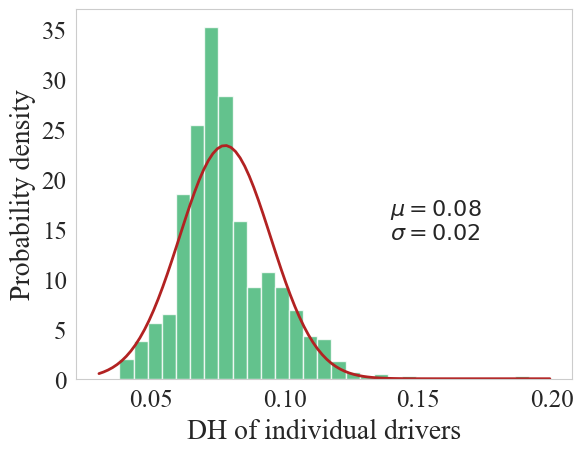

0.07770514185575199 0.017067067017292572


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set global font properties
mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['font.size'] = 16

mse = pd.read_csv("US101_mse_results.csv")
data = np.array(mse)

mu, std = norm.fit(data)
b = np.max(data)
a = np.min(data)
bins = np.linspace(a, b, 30)
plt.hist(data, bins, density=True, alpha=0.8, color='mediumseagreen')

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)

plt.plot(x, p, 'firebrick', linewidth=2)
plt.grid(None)
# 将mu和std的值添加到图上
plt.text(xmax*0.7, p.max()*0.7, r'$\mu={:.2f}$'.format(mu))
plt.text(xmax*0.7, p.max()*0.6, r'$\sigma={:.2f}$'.format(std))

# Set x and y labels
plt.xlabel('DH of individual drivers', fontsize=20)
plt.ylabel('Probability density', fontsize=20)

# Customize tick labels
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Save the figure as a high-resolution PDF
plt.savefig("US101_prob.pdf", dpi=300, format='pdf', bbox_inches='tight')

plt.show()
print(mu, std)